# Multivariate VECM & Johansen Cointegration Trading

**Vector Error Correction Models (VECM) for Statistical Arbitrage**
- Testing $I(1)$ order of integration via Augmented Dickey-Fuller (ADF)
- Johansen Maximum Likelihood Cointegration Rank Determination (Trace & Max Eigenvalue Tests)
- VECM Specification: Long-Run Equilibrium $(\boldsymbol{\beta})$ and Speed of Adjustment $(\boldsymbol{\alpha})$
- Mean-reverting statistical arbitrage spread backtesting

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vecm_cointegration_engine import VECMCointegrationEngine

## 1. Load Data & Stationarity Analysis

In [2]:
engine = VECMCointegrationEngine()
print(f"Loaded {len(engine.data)} trading days")
engine.check_stationarity()

Loaded 1912 trading days


C:\Users\Hitesh\Desktop\resume\09_vecm_cointegration_trading\vecm_cointegration_engine.py:39: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pval, _, _, crit, _ = adfuller(self.data[col].dropna())
C:\Users\Hitesh\Desktop\resume\09_vecm_cointegration_trading\vecm_cointegration_engine.py:40: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat_d1, pval_d1, _, _, _, _ = a

C:\Users\Hitesh\Desktop\resume\09_vecm_cointegration_trading\vecm_cointegration_engine.py:39: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, pval, _, _, crit, _ = adfuller(self.data[col].dropna())
C:\Users\Hitesh\Desktop\resume\09_vecm_cointegration_trading\vecm_cointegration_engine.py:40: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat_d1, pval_d1, _, _, _, _ = a

C:\Users\Hitesh\Desktop\resume\09_vecm_cointegration_trading\vecm_cointegration_engine.py:40: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat_d1, pval_d1, _, _, _, _ = adfuller(self.data[col].diff().dropna())


,Level ADF Stat,Level p-value,Diff ADF Stat,Diff p-value,Is I(1)
Ford,-2.231767,0.194918,-20.493185,0.0,True
General Motors,-1.148996,0.695143,-42.549113,0.0,True
S&P 500,0.078827,0.964585,-21.286216,0.0,True


## 2. Johansen Cointegration Test

In [3]:
jh = engine.run_johansen(["Ford", "General Motors"])
print("=== Trace Statistic Test ===")
display(jh["trace_table"])

print("=== Max Eigenvalue Test ===")
display(jh["max_eig_table"])

print(f"Cointegrating Vector Beta: {jh['beta']}")

=== Trace Statistic Test ===


C:\Users\Hitesh\Desktop\resume\.venv\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:717: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -t * np.sum(tmp, 0)
C:\Users\Hitesh\Desktop\resume\.venv\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:718: ComplexWarning: Casting complex values to real discards the imaginary part
  lr2[i] = -t * np.log(1 - a[i])


,Hypothesis,Trace Stat,90% Crit,95% Crit,99% Crit,Cointegrated (95%)
0,r <= 0,6.609799,13.4294,15.4943,19.9349,False
1,r <= 1,0.645663,2.7055,3.8415,6.6349,False


=== Max Eigenvalue Test ===


,Hypothesis,Max Eig Stat,90% Crit,95% Crit,99% Crit,Cointegrated (95%)
0,r = 0,5.964136,12.2971,14.2639,18.5200,False
1,r = 1,0.645663,2.7055,3.8415,6.6349,False


Cointegrating Vector Beta: [ 1.         -0.02112533]


## 3. Cointegrated Spread Dynamics & Backtest

C:\Users\Hitesh\Desktop\resume\.venv\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:717: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -t * np.sum(tmp, 0)
C:\Users\Hitesh\Desktop\resume\.venv\Lib\site-packages\statsmodels\tsa\vector_ar\vecm.py:718: ComplexWarning: Casting complex values to real discards the imaginary part
  lr2[i] = -t * np.log(1 - a[i])


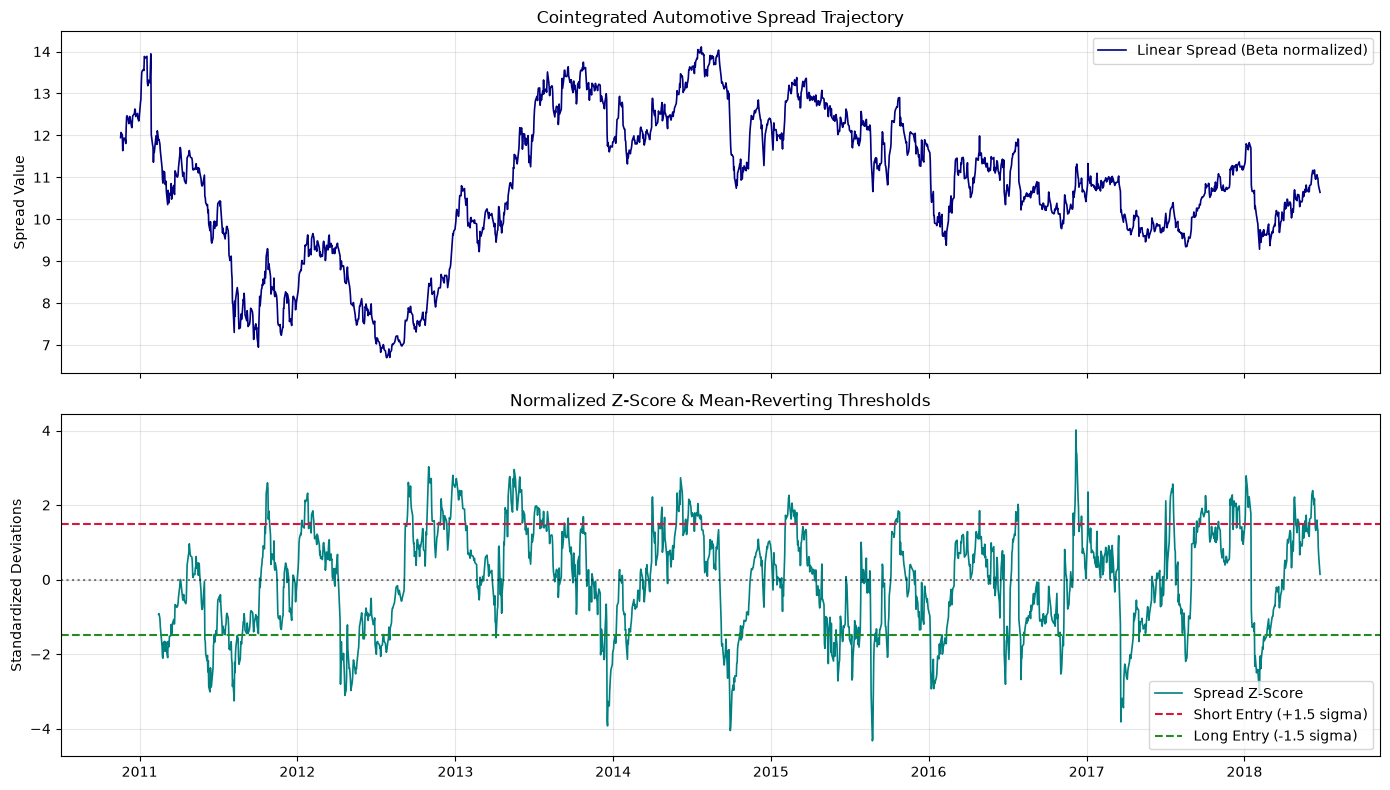

In [4]:
bt = engine.backtest_statistical_arbitrage(["Ford", "General Motors"], entry_z=1.5, exit_z=0.2)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(bt["spread"], color="navy", lw=1.2, label="Linear Spread (Beta normalized)")
ax1.set_title("Cointegrated Automotive Spread Trajectory")
ax1.set_ylabel("Spread Value")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(bt["z_score"], color="teal", lw=1.2, label="Spread Z-Score")
ax2.axhline(1.5, color="crimson", linestyle="--", label="Short Entry (+1.5 sigma)")
ax2.axhline(-1.5, color="forestgreen", linestyle="--", label="Long Entry (-1.5 sigma)")
ax2.axhline(0.0, color="black", linestyle=":", alpha=0.5)
ax2.set_title("Normalized Z-Score & Mean-Reverting Thresholds")
ax2.set_ylabel("Standardized Deviations")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()